In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

In [2]:
models = ["TabMLP", "Ridge", "LightGBM"]

pairs = [
    ("LightGBM", "TabMLP"),
    ("LightGBM", "Ridge"),
    ("TabMLP", "Ridge"),
]

In [3]:
df = pd.read_parquet("../predictions.parquet")

required_columns = ["y_true"] + models
missing_columns = set(required_columns) - set(df.columns)

if missing_columns:
    raise ValueError(f"Missing columns: {sorted(missing_columns)}")

In [5]:
residual_columns = {}

for model in models:
    residual_col = f"{model}_residual"
    residual_columns[model] = residual_col
    df[residual_col] = df["y_true"] - df[model]

residuals = [residual_columns[m] for m in models]

df[["y_true"] + models + residuals].head()

,y_true,TabMLP,Ridge,LightGBM,TabMLP_residual,Ridge_residual,LightGBM_residual
364426,51.3,60.560841,60.881483,61.082794,-9.260841,-9.581483,-9.782794
224752,50.6,47.683277,47.961607,47.965610,2.916723,2.638393,2.634390
110423,79.9,62.449707,61.987044,61.743480,17.450293,17.912956,18.156520
272555,55.4,59.435585,58.288838,60.159748,-4.035585,-2.888838,-4.759748
199651,50.4,48.599228,48.549959,46.416592,1.800772,1.850041,3.983408


In [6]:
def calculate_metrics(y_true, y_pred):
    residuals = y_true - y_pred

    return {
        "RMSE": np.sqrt(np.mean(residuals**2)),
        "MAE": np.mean(np.abs(residuals)),
        "Bias": np.mean(residuals),
        "Residual std": np.std(residuals, ddof=1),
        "Prediction-target corr": np.corrcoef(y_true, y_pred)[0, 1],
    }


model_metrics = pd.DataFrame(
    {
        model: calculate_metrics(df["y_true"].to_numpy(), df[model].to_numpy())
        for model in models
    }
).T

model_metrics.index.name = "Model"

model_metrics.sort_values("RMSE")

,RMSE,MAE,Bias,Residual std,Prediction-target corr
Model,,,,,
LightGBM,8.747615,6.972921,0.025370,8.747613,0.885914
TabMLP,8.840737,7.056353,-0.034662,8.840704,0.883315
Ridge,8.883888,7.090298,0.019865,8.883901,0.882093


,TabMLP,Ridge,LightGBM
TabMLP,1.000000,0.993077,0.991047
Ridge,0.993077,1.000000,0.987370
LightGBM,0.991047,0.987370,1.000000


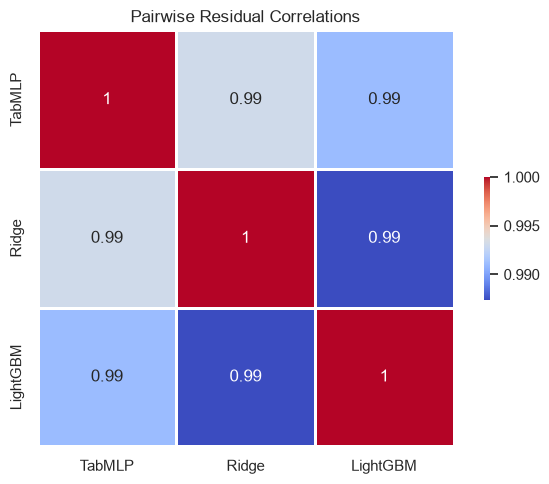

In [8]:
residual_df = df[residuals].copy()
residual_df.columns = models

residual_corr = residual_df.corr(method="pearson")

display(residual_corr)

plt.figure(figsize=(7, 5))

sns.heatmap(
    residual_corr,
    annot=True,
    square=True,
    cmap="coolwarm",
    vmax=1,
    cbar_kws={"fraction": 0.01},
    linewidth=2,
)

plt.title("Pairwise Residual Correlations")
plt.tight_layout()
plt.show()

In [7]:
ensemble_predictions = {}
ensemble_rows = []

for model_a, model_b in pairs:
    ensemble_name = f"{model_a} + {model_b}"
    ensemble_pred = (df[model_a] + df[model_b]) / 2

    ensemble_predictions[ensemble_name] = ensemble_pred

    metrics = calculate_metrics(df["y_true"].to_numpy(), ensemble_pred.to_numpy())

    best_individual_rmse = min(
        model_metrics.loc[model_a, "RMSE"],
        model_metrics.loc[model_b, "RMSE"],
    )

    metrics["Best individual RMSE"] = best_individual_rmse
    metrics["RMSE improvement"] = best_individual_rmse - metrics["RMSE"]
    metrics["Improvement (%)"] = (
        100 * metrics["RMSE improvement"] / best_individual_rmse
    )

    ensemble_rows.append(
        {
            "Ensemble": ensemble_name,
            **metrics,
        }
    )

ensemble_metrics = pd.DataFrame(ensemble_rows).set_index("Ensemble")

ensemble_metrics.sort_values("RMSE")

,RMSE,MAE,Bias,Residual std,Prediction-target corr,Best individual RMSE,RMSE improvement,Improvement (%)
Ensemble,,,,,,,,
LightGBM + TabMLP,8.774421,6.999098,-0.004646,8.774454,0.885167,8.747615,-0.026806,-0.306437
LightGBM + Ridge,8.787873,7.008091,0.022618,8.787878,0.884792,8.747615,-0.040258,-0.460214
TabMLP + Ridge,8.846920,7.057871,-0.007398,8.846952,0.883136,8.840737,-0.006183,-0.069935


In [8]:
lgb_error = df["LightGBM_residual"].abs()
threshold = lgb_error.quantile(0.9)

hard_mask = lgb_error >= threshold

conditional_rows = []

y_true = df["y_true"]

for model in models:
    model_abs_error = (y_true - df[model]).abs()

    conditional_rows.append(
        {
            "Model": model,
            "Overall MAE": model_abs_error.mean(),
            "Hard-subset MAE": model_abs_error[hard_mask].mean(),
            "Hard-subset RMSE": np.sqrt(
                np.mean((y_true[hard_mask] - df.loc[hard_mask, model]) ** 2)
            ),
        }
    )

for ensemble_name, ensemble_pred in ensemble_predictions.items():
    errors = (y_true - ensemble_pred).abs()

    conditional_rows.append(
        {
            "Model": ensemble_name,
            "Overall MAE": errors.mean(),
            "Hard-subset MAE": errors[hard_mask].mean(),
            "Hard-subset RMSE": np.sqrt(
                np.mean((y_true[hard_mask] - ensemble_pred[hard_mask]) ** 2)
            ),
        }
    )

conditional_metrics = pd.DataFrame(conditional_rows).set_index("Model")

conditional_metrics.sort_values("Hard-subset RMSE")

,Overall MAE,Hard-subset MAE,Hard-subset RMSE
Model,,,
LightGBM,6.972921,18.075582,18.382744
LightGBM + Ridge,7.008091,18.073175,18.388429
LightGBM + TabMLP,6.999098,18.078777,18.394161
TabMLP + Ridge,7.057871,18.076371,18.415607
Ridge,7.090298,18.070769,18.419477
TabMLP,7.056353,18.081973,18.424629


In [9]:
lgb_abs_error = df["LightGBM_residual"].abs()

conditional_win_rows = []

for model in ["TabMLP", "Ridge"]:
    alternative_abs_error = df[f"{model}_residual"].abs()

    conditional_win_rows.append(
        {
            "Model": model,
            "Win rate on LightGBM hard subset": (
                alternative_abs_error[hard_mask] < lgb_abs_error[hard_mask]
            ).mean(),
            "Tie rate": (
                alternative_abs_error[hard_mask] == lgb_abs_error[hard_mask]
            ).mean(),
            "Mean absolute error difference": (
                lgb_abs_error[hard_mask] - alternative_abs_error[hard_mask]
            ).mean(),
        }
    )

conditional_win_rates = pd.DataFrame(conditional_win_rows).set_index("Model")

conditional_win_rates

,Win rate on LightGBM hard subset,Tie rate,Mean absolute error difference
Model,,,
TabMLP,0.498571,0.0,-0.006391
Ridge,0.501429,0.0,0.004813


In [10]:
residual_summary = pd.DataFrame(
    {
        model: {
            "Mean residual": df[f"{model}_residual"].mean(),
            "Residual std": df[f"{model}_residual"].std(),
            "Median residual": df[f"{model}_residual"].median(),
            "Residual skewness": df[f"{model}_residual"].skew(),
            "95th percentile |error|": df[f"{model}_residual"].abs().quantile(0.95),
            "Maximum |error|": df[f"{model}_residual"].abs().max(),
        }
        for model in models
    }
).T

residual_summary

,Mean residual,Residual std,Median residual,Residual skewness,95th percentile |error|,Maximum |error|
TabMLP,-0.034662,8.840704,0.055631,-0.024783,17.324541,47.446281
Ridge,0.019865,8.883901,0.085185,-0.021269,17.386083,46.994761
LightGBM,0.025370,8.747613,0.112837,-0.021681,17.135361,46.784038


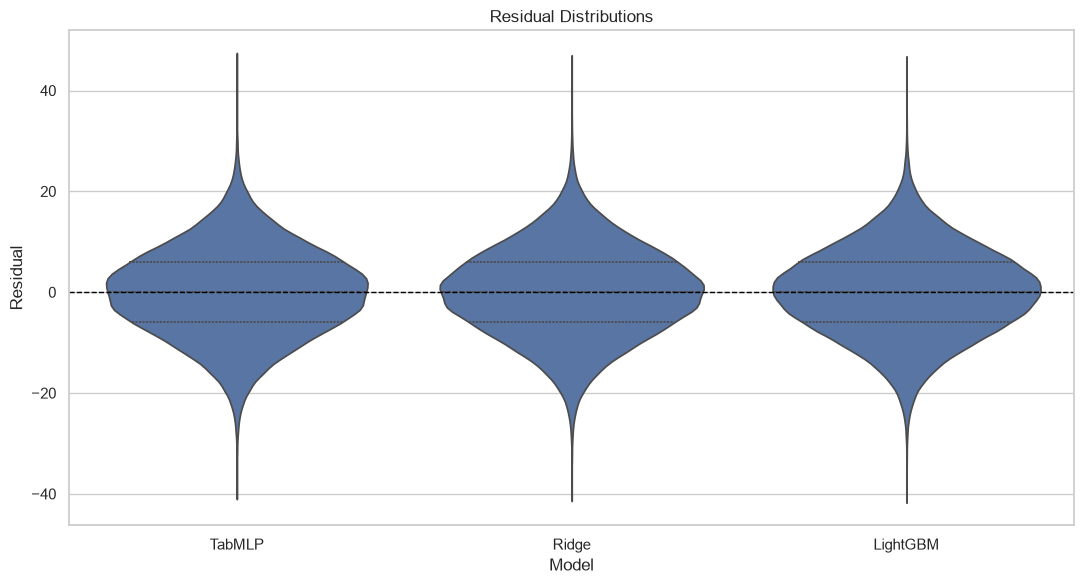

In [11]:
residual_long = (
    df[residuals]
    .rename(columns={residual_columns[m]: m for m in models})
    .melt(
        var_name="Model",
        value_name="Residual",
    )
)

plt.figure(figsize=(11, 6))

sns.violinplot(
    data=residual_long,
    x="Model",
    y="Residual",
    inner="quartile",
    cut=0,
)

plt.axhline(0, color="black", linestyle="--", linewidth=1)
plt.title("Residual Distributions")
plt.tight_layout()
plt.show()

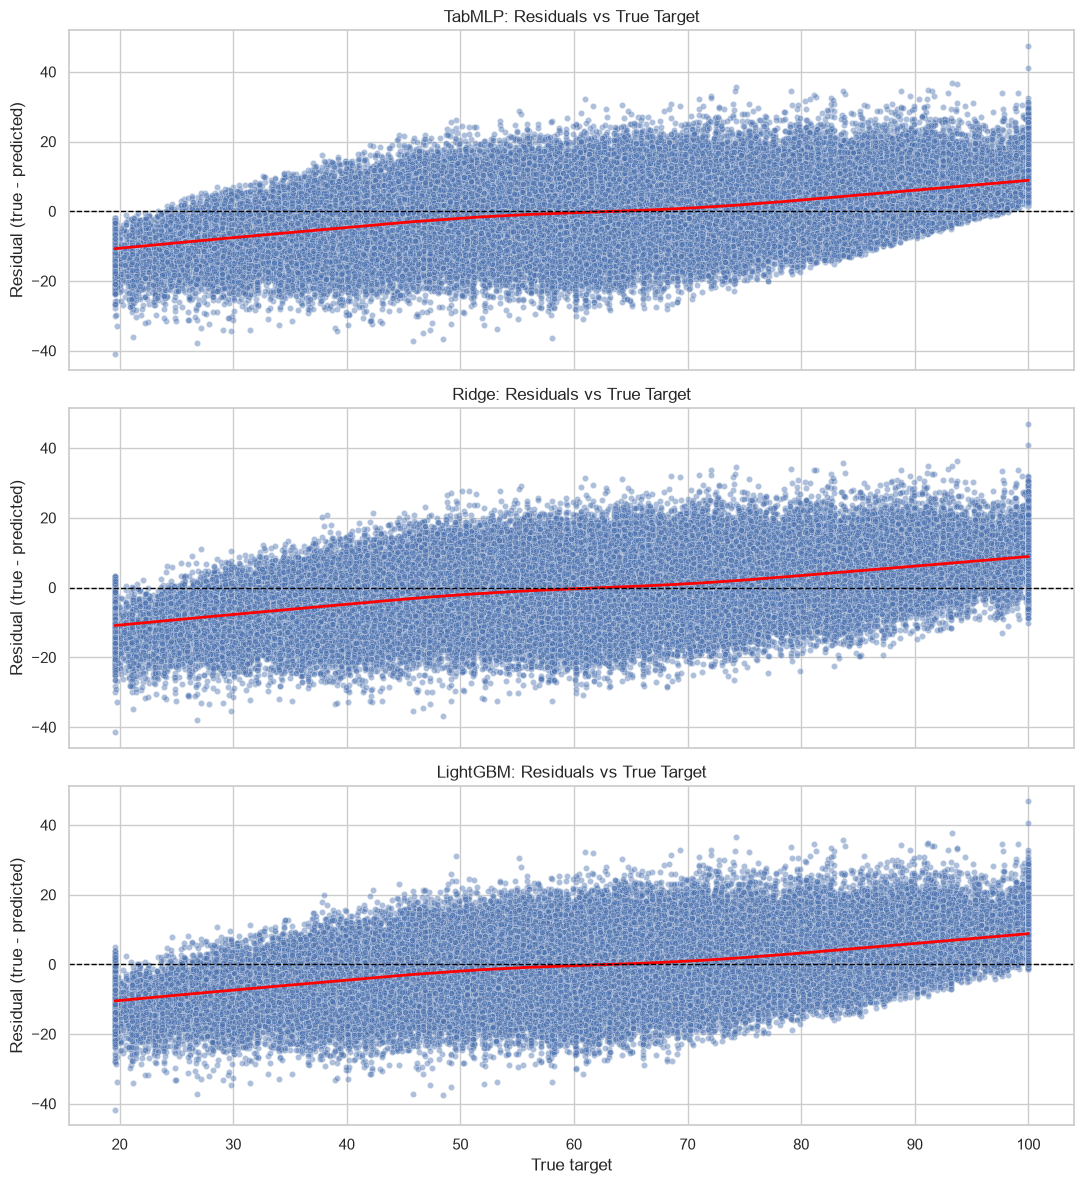

In [12]:
fig, axes = plt.subplots(
    nrows=len(models),
    ncols=1,
    figsize=(11, 4 * len(models)),
    sharex=True,
)

for ax, model in zip(axes, models):
    sns.scatterplot(
        x=df["y_true"],
        y=df[f"{model}_residual"],
        alpha=0.45,
        s=20,
        ax=ax,
    )

    sns.regplot(
        x=df["y_true"],
        y=df[f"{model}_residual"],
        scatter=False,
        lowess=True,
        color="red",
        line_kws={"linewidth": 2},
        ax=ax,
    )

    ax.axhline(0, color="black", linestyle="--", linewidth=1)
    ax.set_title(f"{model}: Residuals vs True Target")
    ax.set_ylabel("Residual (true - predicted)")

axes[-1].set_xlabel("True target")

plt.tight_layout()
plt.show()

In [14]:
comparison_rows = []

for model in models:
    comparison_rows.append(
        {
            "Candidate": model,
            "Type": "Individual",
            "RMSE": model_metrics.loc[model, "RMSE"],
            "MAE": model_metrics.loc[model, "MAE"],
            "Bias": model_metrics.loc[model, "Bias"],
            "Residual std": model_metrics.loc[model, "Residual std"],
            "Residual correlation": np.nan,
        }
    )

for model_a, model_b in pairs:
    ensemble_name = f"{model_a} + {model_b}"

    comparison_rows.append(
        {
            "Candidate": ensemble_name,
            "Type": "Ensemble",
            "RMSE": ensemble_metrics.loc[ensemble_name, "RMSE"],
            "MAE": ensemble_metrics.loc[ensemble_name, "MAE"],
            "Bias": ensemble_metrics.loc[ensemble_name, "Bias"],
            "Residual std": ensemble_metrics.loc[ensemble_name, "Residual std"],
            "Residual correlation": residual_corr.loc[model_a, model_b],
        }
    )

final_comparison = (
    pd.DataFrame(comparison_rows).sort_values("RMSE").reset_index(drop=True)
)

display(final_comparison.round(6))

best_individual = model_metrics["RMSE"].idxmin()
best_ensemble = ensemble_metrics["RMSE"].idxmin()

print(f"Best individual model: {best_individual}")
print(f"Best pairwise ensemble: {best_ensemble}")
print(
    "Best individual RMSE:",
    f"{model_metrics.loc[best_individual, 'RMSE']:.6f}",
)
print(
    "Best pairwise ensemble RMSE:",
    f"{ensemble_metrics.loc[best_ensemble, 'RMSE']:.6f}",
)

improvement = (
    model_metrics.loc[best_individual, "RMSE"]
    - ensemble_metrics.loc[best_ensemble, "RMSE"]
)

print(f"Absolute RMSE improvement: {improvement:.6f}")
print(
    "Relative RMSE improvement:",
    f"{100 * improvement / model_metrics.loc[best_individual, 'RMSE']:.3f}%",
)

,Candidate,Type,RMSE,MAE,Bias,Residual std,Residual correlation
0,LightGBM,Individual,8.747615,6.972921,0.025370,8.747613,NaN
1,LightGBM + TabMLP,Ensemble,8.774421,6.999098,-0.004646,8.774454,0.991047
2,LightGBM + Ridge,Ensemble,8.787873,7.008091,0.022618,8.787878,0.987370
3,TabMLP,Individual,8.840737,7.056353,-0.034662,8.840704,NaN
4,TabMLP + Ridge,Ensemble,8.846920,7.057871,-0.007398,8.846952,0.993077
5,Ridge,Individual,8.883888,7.090298,0.019865,8.883901,NaN


Best individual model: LightGBM
Best pairwise ensemble: LightGBM + TabMLP
Best individual RMSE: 8.747615
Best pairwise ensemble RMSE: 8.774421
Absolute RMSE improvement: -0.026806
Relative RMSE improvement: -0.306%


In [5]:
import optuna
from sklearn.metrics import root_mean_squared_error

optuna.logging.set_verbosity(optuna.logging.WARNING)

oof_lgbm = df["LightGBM"].values
oof_tabmlp = df["TabMLP"].values
oof_ridge = df["Ridge"].values

y = df["y_true"].values


def objective(trial: optuna.Trial):
    w_lgbm = trial.suggest_float("w_lgbm", 0.0, 1.0)
    w_tabmlp = trial.suggest_float("w_tabmlp", 0.0, 1.0)
    w_ridge = trial.suggest_float("w_ridge", 0.0, 1.0)

    weights = [w_lgbm, w_tabmlp, w_ridge]
    weights = [w / sum(weights) for w in weights]

    pred = weights[0] * oof_lgbm + weights[1] * oof_tabmlp + weights[2] * oof_ridge

    return root_mean_squared_error(y, pred)


sampler = optuna.samplers.TPESampler(seed=42)
study = optuna.create_study(direction="minimize", sampler=sampler)
study.optimize(
    objective,
    n_trials=1000,
    show_progress_bar=True,
)

print("Best params:", study.best_params)
print("Best RMSE:", study.best_value)

best_params = study.best_params
weights = [
    best_params["w_lgbm"],
    best_params["w_tabmlp"],
    best_params["w_ridge"],
]
weights = [w / sum(weights) for w in weights]

print(f"LightGBM: {weights[0]:.4f}")
print(f"TabMLP:   {weights[1]:.4f}")
print(f"Ridge:    {weights[2]:.4f}")

oof_ensemble = weights[0] * oof_lgbm + weights[1] * oof_tabmlp + weights[2] * oof_ridge

print("Ensemble RMSE:", root_mean_squared_error(y, oof_ensemble))

  0%|          | 0/1000 [00:00<?, ?it/s]

Best params: {'w_lgbm': 0.9046239597707827, 'w_tabmlp': 0.0002066069736754673, 'w_ridge': 4.744646468278664e-05}
Best RMSE: 8.747619263434505
LightGBM: 0.9997
TabMLP:   0.0002
Ridge:    0.0001
Ensemble RMSE: 8.747619263434505
